# CST4215 Assessment 1: Portfolio_M01151993
**Dataset:** Amazon E-commerce (Products and Review sheets).

**Problem Statement:** A marketplace team wants to flag products likely to disappoint customers early, so that we can decide to whether drop the products that has a low score or come up with marketing strategies to improve them.

**KPI:** Customer Experience Index (CXI) per product = 0.5 x (mean rating / 5) + 0.3 x (mean normalised sentiment) + 0.2 x (share of reviews with >= 1 helpful vote)  
**Task:** regression of CXI from product attributes (Ridge vs Random Forest, with a mean baseline).

## 1. Setup

In [ ]:
import numpy as np
import pandas as pd

RANDOM_STATE = 42
products =pd.read_csv("/content/products.csv") #Adding the path for CSV
reviews=pd.read_csv("/content/reviews.csv") #Adding the path for CSV

MIN_REVIEWS = 5                   # products with fewer reviews give a noisy KPI

SENT_MIN, SENT_MAX = -1.0, 1.0    #Setting the sentiment score in this range, because the data in this attribute lies within these two numbers

print(products.info())
print(reviews.info())

print('Dimensions of the dataset:',products.shape, reviews.shape)

reviews[["rating", "helpfulVoteCount", "sentiment_score"]].describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 728 entries, 0 to 727
Data columns (total 34 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   s.no                       728 non-null    int64  
 1   about_item                 728 non-null    object 
 2   asin                       728 non-null    object 
 3   availability               715 non-null    object 
 4   best_sellers_rank          558 non-null    object 
 5   brand_name                 728 non-null    object 
 6   brand_page_url             649 non-null    object 
 7   breadcrumbs                715 non-null    object 
 8   customer_review_summary    634 non-null    object 
 9   default_variant/0          696 non-null    object 
 10  default_variant/1          658 non-null    object 
 11  default_variant/2          1 non-null      object 
 12  delivery_date              702 non-null    object 
 13  fastest_delivery_date      667 non-null    object 

,rating,helpfulVoteCount,sentiment_score
count,6320.000000,6327.000000,6327.000000
mean,4.533228,3.336336,0.307545
std,0.855710,19.090762,0.218020
min,1.000000,0.000000,-1.000000
25%,4.000000,0.000000,0.168568
50%,5.000000,0.000000,0.300000
75%,5.000000,2.000000,0.450000
max,5.000000,710.000000,1.000000


## 2. Build the KPI
**CXI = 0.5 x (mean rating / 5) + 0.3 x (mean normalised sentiment) + 0.2 x (share of reviews with at least one helpful vote)**

Built from three review attributes: `rating`, `sentiment_score`, `helpfulVoteCount`. All parts lie in [0, 1], so CXI lies in [0, 1].
##### Since `rating` has the most influence I am giving it the most weightage and followed by the `sentiment_score` and `helpfulvotecount` attributes.

In [ ]:
# Row-level components
reviews["helpful_flag"] = (reviews["helpfulVoteCount"].fillna(0) > 0).astype(int)
reviews["sent_norm"] = ((reviews["sentiment_score"] - SENT_MIN) / (SENT_MAX - SENT_MIN)).clip(0, 1)

# Aggregating all the reviews to one row per product since one product has many reviews
agg = (reviews.groupby("productASIN")
       .agg(n_reviews=("rating", "size"),
            mean_rating=("rating", "mean"),
            mean_sent=("sent_norm", "mean"),
            helpful_share=("helpful_flag", "mean"))
       .reset_index())

print("Products with reviews:", len(agg))
agg = agg[agg["n_reviews"] >= MIN_REVIEWS].copy()
print(f"Products with >= {MIN_REVIEWS} reviews:", len(agg))

#Creating the CXI attribute
agg["CXI"] = (0.5 * (agg["mean_rating"] / 5)
              + 0.3 * agg["mean_sent"]
              + 0.2 * agg["helpful_share"])
agg["CXI"].describe()

Products with reviews: 700
Products with >= 5 reviews: 622


,CXI
count,622.000000
mean,0.702118
std,0.057066
min,0.429167
25%,0.673234
50%,0.706985
75%,0.739720
max,0.857170


## 3. Merge with product attributes

Merging the Products sheet with the Reviews sheet with the product ids.

In [ ]:
df = products.merge(agg, left_on="asin", right_on="productASIN", how="inner")
print(df.shape)

(622, 40)


## 4. Feature engineering
The followings functions are used to do the preprocessing of the data.

In [ ]:
import re
def to_num(s):
    #This function is used to convert the currency symbols/commas and convert to float in the reviews.
    return pd.to_numeric(s.astype(str).str.replace(r"[^0-9.]", "", regex=True), errors="coerce")

def parse_count(x):
    #This is function is used to convert values like 1K+ to 1000, so that the model can understand the reviews.
    if pd.isna(x):
        return 0.0
    m = re.search(r"([\d.]+)\s*([KkMm]?)", str(x))
    if not m:
        return 0.0
    val = float(m.group(1))
    return val * {"k": 1e3, "m": 1e6, "": 1}[m.group(2).lower()]

def first_number(x):
    #This function is used to convert the first integer in a string such as '#1,234 in Electronics' to model readable values.
    m = re.search(r"[\d,]+", str(x))
    return float(m.group().replace(",", "")) if m else np.nan

df["price"] = to_num(df["price_value"])
df["list_price_num"] = to_num(df["list_price"])

#I am considering that if the list_price is missing, then most likely that means no discount for the prodcut and treat list price as the selling price
df["list_price_num"] = df["list_price_num"].fillna(df["price"])
df["discount_pct"] = ((df["list_price_num"] - df["price"]) / df["list_price_num"]).clip(lower=0).fillna(0)

df["recent_purchases_num"] = df["recent_purchases"].apply(parse_count)
df["bsr_num"] = df["best_sellers_rank"].apply(first_number)
df["has_bsr"] = df["bsr_num"].notna().astype(int)

# Text-based features
df["about_len"] = df["about_item"].fillna("").str.split().str.len()
df["title_len"] = df["title"].fillna("").str.split().str.len()

# Brand: keep frequent brands as top_brands and grouping the other brand into a section as Other
top_brands = df["brand_name"].value_counts().head(20).index
df["brand_grp"] = df["brand_name"].where(df["brand_name"].isin(top_brands), "Other")

df[["price", "discount_pct", "recent_purchases_num", "bsr_num", "about_len"]].describe()#Showing how the values under these attributes look like

,price,discount_pct,recent_purchases_num,bsr_num,about_len
count,612.000000,622.000000,622.000000,4.880000e+02,622.000000
mean,34.448239,0.140658,521.463023,7.391810e+04,104.363344
std,23.974628,0.171202,971.163096,7.541842e+05,65.963537
min,5.457300,0.000000,0.000000,1.000000e+00,3.000000
25%,19.990000,0.000000,62.500000,7.757500e+02,45.000000
50%,28.646400,0.063415,200.000000,2.914000e+03,101.500000
75%,41.657400,0.258848,600.000000,1.243325e+04,153.000000
max,174.990000,0.727135,10000.000000,1.492000e+07,315.000000


## 5. Columns removed from the input
- **Target leakage:** `rating_stars`, `rating_count`, `rating_distribution/*`, `customer_review_summary` and the aggregated review columns all describe customer satisfaction, which are the values CXI measures.
- **Identifiers / URLs / timestamps:** no predictive meaning.
- **Mostly empty:** `default_variant/2`, `model_number`, `manufacturer`, `product_description`.

In [ ]:
#Leakage_cols has the columns which will lead to target leakage.
leakage_cols = ["rating_stars", "rating_count", "customer_review_summary",
                "rating_distribution/1star", "rating_distribution/2star",
                "rating_distribution/3star", "rating_distribution/4star",
                "rating_distribution/5star",
                "n_reviews", "mean_rating", "mean_sent", "helpful_share"]

#id_cols are the columns that does not influence the KPI.
id_cols = ["s.no", "asin", "productASIN", "brand_page_url", "product_url", "seller_page_url",
           "all_images", "scrape_time", "default_variant/0", "default_variant/1",
           "delivery_date", "fastest_delivery_date"]

#empty_cols are the columns that are mostly empty.
empty_cols = ["default_variant/2", "model_number", "manufacturer", "product_description"]

#raw_replaced are the columns that we will be using as engineered versions
raw_replaced = ["price_value", "list_price", "recent_purchases", "best_sellers_rank",
                "rank_1", "brand_name", "seller_name", "breadcrumbs"]

#Dropping columns from the dataset for getting the input for training the model
drop_cols = [c for c in leakage_cols + id_cols + empty_cols + raw_replaced if c in df.columns]
model_df = df.drop(columns=drop_cols)
print("Remaining columns:", list(model_df.columns))

Remaining columns: ['about_item', 'availability', 'title', 'CXI', 'price', 'list_price_num', 'discount_pct', 'recent_purchases_num', 'bsr_num', 'has_bsr', 'about_len', 'title_len', 'brand_grp']


## 6. Independence test (Spearman) between numeric features and CXI
Values close to +/-1 would indicate target leakage.

In [ ]:
from scipy.stats import spearmanr

num_cols = model_df.select_dtypes(include="number").columns.drop("CXI")#Dropping the CXI as that is the KPI
rows = []
for col in num_cols:
    valid = model_df[[col, "CXI"]].dropna()          # pairwise-complete observations
    rho, pval = spearmanr(valid[col], valid["CXI"])
    rows.append({"feature": col, "spearman_rho": rho, "p_value": pval, "n": len(valid)})
corr = (pd.DataFrame(rows).set_index("feature")
        .sort_values("spearman_rho", key=abs, ascending=False))
corr.round(4)   # |rho| close to 1 would signal target leakage

,spearman_rho,p_value,n
feature,,,
bsr_num,-0.4140,0.0000,488
recent_purchases_num,0.4071,0.0000,622
discount_pct,0.1030,0.0102,622
list_price_num,0.0595,0.1418,612
title_len,-0.0510,0.2036,622
has_bsr,-0.0335,0.4043,622
price,0.0270,0.5045,612
about_len,-0.0091,0.8201,622


**Optional leakage sanity check:** the platform-level `rating_stars` (dropped above) should correlate with CXI, which is exactly why it must not be a model input.

In [ ]:
check = pd.DataFrame({"rating_stars": df["rating_stars"].astype(str).str.extract(r"([\d.]+)")[0].astype(float),
                        "CXI": df["CXI"]}).dropna()
print("Spearman(rating_stars, CXI):", round(check["rating_stars"].corr(check["CXI"], method="spearman"), 3))

Spearman(rating_stars, CXI): 0.26


## 7. Setup and extra features

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, PredefinedSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# True  -> tune with 5-fold CV *inside the training set* (test set untouched)
# False -> tune with one fixed validation split carved out of the training set
USE_CV_FOR_TUNING = True

In [ ]:
def top_k(s, k):
    """Keep the k most frequent values, group the rest as 'Other'."""
    keep = s.value_counts().head(k).index
    return s.where(s.isin(keep), "Other")

data = model_df.copy()

# Category = first element of the breadcrumb path.
bc = df["breadcrumbs"].astype(str).str.split(r"[>\u203a|]", regex=True).str[0].str.strip()
print(bc.value_counts().head(10))
data["category"] = top_k(bc, 8)

data["availability_grp"] = top_k(data["availability"].fillna("Unknown").astype(str), 5)
data["about_item"] = data["about_item"].fillna("").astype(str)

print(data["availability_grp"].value_counts())

breadcrumbs
Clothing, Shoes & Jewelry    614
nan                            7
Sports & Outdoors              1
Name: count, dtype: int64
availability_grp
In Stock                              564
Other                                  19
Only 1 left in stock - order soon.     12
Unknown                                10
Only 3 left in stock - order soon.      9
In stock                                8
Name: count, dtype: int64


## 8. Train-test split (80/20)
Each row is one product, so a plain random split cannot leak reviews of the same product across sets. All imputers, scalers, encoders and the TF-IDF vocabulary are fitted on the training set only (inside the pipeline).

In [ ]:
log_cols = ["price", "list_price_num", "recent_purchases_num", "bsr_num"]   # right-skewed -> log1p
lin_cols = ["discount_pct", "about_len", "title_len", "has_bsr"]
cat_cols = ["brand_grp", "category", "availability_grp"]
text_col = "about_item"

X = data[log_cols + lin_cols + cat_cols + [text_col]]
y = data["CXI"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(497, 12) (125, 12)


## 9. Preprocessing pipeline
- Skewed numerics: `log1p`, median imputation, standard scaling (needed for Ridge)
- Other numerics: median imputation, standard scaling
- Categoricals: most-frequent imputation, one-hot encoding
- `about_item` text: TF-IDF (top 100 terms, English stop words removed)

In [ ]:
def make_preprocessor():
    num_log = Pipeline([("log", FunctionTransformer(np.log1p)),
                        ("imp", SimpleImputer(strategy="median")),
                        ("sc", StandardScaler())])
    num_lin = Pipeline([("imp", SimpleImputer(strategy="median")),
                        ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    txt = TfidfVectorizer(stop_words="english", max_features=100, min_df=5)
    return ColumnTransformer([("log", num_log, log_cols),
                              ("lin", num_lin, lin_cols),
                              ("cat", cat, cat_cols),
                              ("txt", txt, text_col)])

## 10. Models, hyperparameter tuning and evaluation
Problem type: **regression**. Models: a mean-prediction baseline, **Ridge** and **Random Forest**. Tuning uses the training set only; the test set is used once, for the final scores.

Metrics: **R2** (variance explained), **MAE** (average error in CXI units) and **RMSE** (penalises large errors).

In [ ]:
if USE_CV_FOR_TUNING:
    tune_cv = 5
else:
    n = len(X_train)
    fold = np.full(n, -1)
    fold[np.random.RandomState(RANDOM_STATE).choice(n, int(0.2 * n), replace=False)] = 0
    tune_cv = PredefinedSplit(fold)

models = {
    "Baseline (mean)": (DummyRegressor(strategy="mean"), {}),
    "Ridge": (Ridge(), {"model__alpha": [0.1, 1, 10, 50, 100, 300]}),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
                      {"model__n_estimators": [200, 400],
                       "model__max_depth": [None, 6, 12],
                       "model__min_samples_leaf": [1, 3, 5],
                       "model__max_features": ["sqrt", 0.5]}),
}

results, fitted = [], {}
for name, (est, grid) in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", est)])
    if grid:
        search = GridSearchCV(pipe, grid, cv=tune_cv,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
        search.fit(X_train, y_train)
        best = search.best_estimator_
        print(f"{name} best params: {search.best_params_}")
    else:
        best = pipe.fit(X_train, y_train)
    fitted[name] = best
    for split, Xs, ys in [("train", X_train, y_train), ("test", X_test, y_test)]:
        pred = best.predict(Xs)
        results.append({"model": name, "split": split,
                        "R2": r2_score(ys, pred),
                        "MAE": mean_absolute_error(ys, pred),
                        "RMSE": np.sqrt(mean_squared_error(ys, pred))})

res = pd.DataFrame(results)
res_table = res.pivot(index="model", columns="split", values=["R2", "MAE", "RMSE"]).round(4)
res_table

Ridge best params: {'model__alpha': 10}
Random Forest best params: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}


R2             MAE            RMSE        
split              test   train    test   train    test   train
model                                                          
Baseline (mean) -0.0078  0.0000  0.0447  0.0423  0.0590  0.0565
Random Forest    0.3201  0.8011  0.0380  0.0179  0.0485  0.0252
Ridge            0.3623  0.4340  0.0374  0.0322  0.0469  0.0425

### 11. Results chart

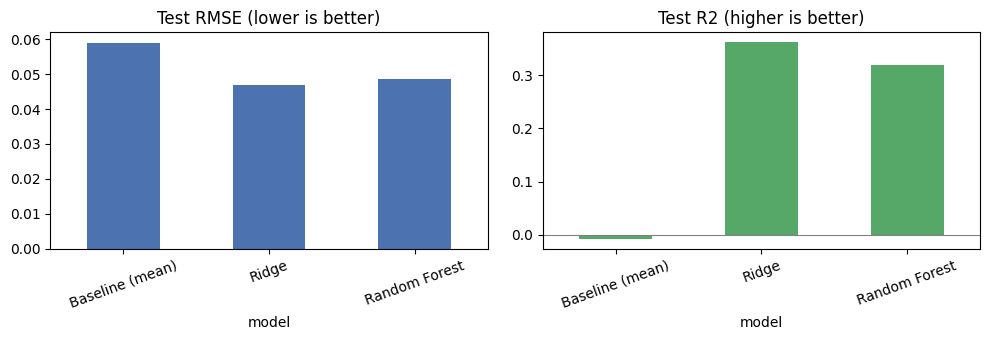

In [ ]:
test_res = res[res["split"] == "test"].set_index("model")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
test_res["RMSE"].plot.bar(ax=ax[0], color="#4C72B0", title="Test RMSE (lower is better)", rot=20)
test_res["R2"].plot.bar(ax=ax[1], color="#55A868", title="Test R2 (higher is better)", rot=20)
ax[1].axhline(0, color="grey", lw=0.8)
plt.tight_layout()
plt.show()

## 12. Key drivers of CXI
Permutation importance on the **test set** for the Random Forest: how much R2 drops when one input is shuffled. `about_item` is treated as a single text feature. The partial-dependence plots below are computed manually, because sklearn's built-in version fails on columns with missing values (e.g. `bsr_num`).

recent_purchases_num    0.2203
bsr_num                 0.1060
about_item              0.0632
category                0.0351
has_bsr                 0.0213
list_price_num          0.0116
price                   0.0084
about_len               0.0082
discount_pct            0.0018
title_len              -0.0004
availability_grp       -0.0005
brand_grp              -0.0015
dtype: float64


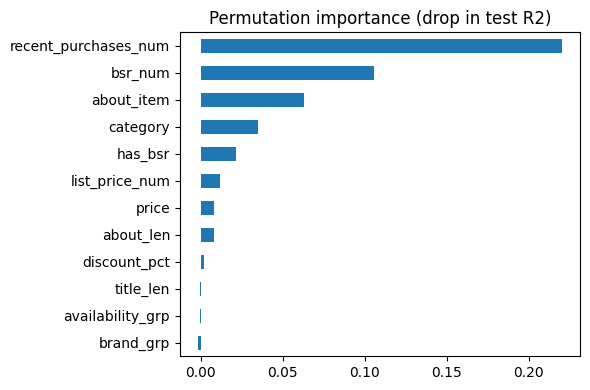

In [ ]:
rf = fitted["Random Forest"]
pi = permutation_importance(rf, X_test, y_test, n_repeats=30,
                            random_state=RANDOM_STATE, scoring="r2")
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
print(imp.round(4))

imp.sort_values().plot.barh(figsize=(6, 4), title="Permutation importance (drop in test R2)")
plt.tight_layout()
plt.show()

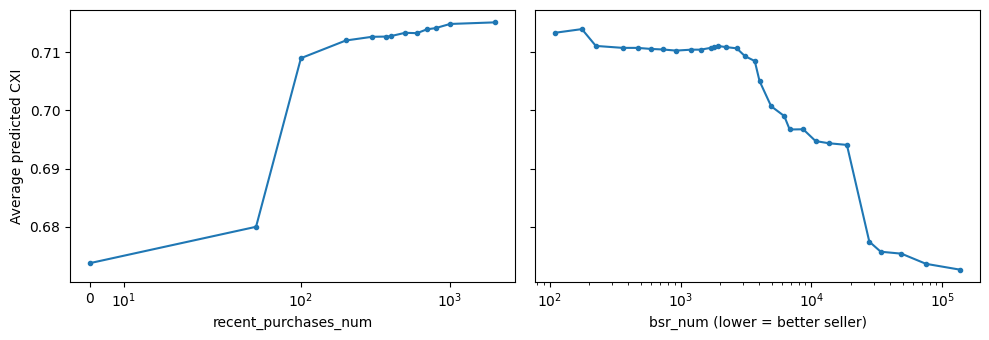

In [ ]:
def manual_pdp(model, X, col, grid, forced=None):
    #Average predicted CXI when `col` is set to each grid value for every row.
    out = []
    for g in grid:
        Xg = X.copy()
        Xg[col] = g
        for k, v in (forced or {}).items():
            Xg[k] = v
        out.append(model.predict(Xg).mean())
    return np.array(out)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)

# recent purchases (missing was coded as 0, so 0 means 'no badge / under threshold')
g1 = np.unique(np.percentile(X_train["recent_purchases_num"], np.linspace(0, 95, 30)))
ax[0].plot(g1, manual_pdp(rf, X_train, "recent_purchases_num", g1), marker="o", ms=3)
ax[0].set_xscale("symlog", linthresh=50)
ax[0].set_xlabel("recent_purchases_num")
ax[0].set_ylabel("Average predicted CXI")

# best-seller rank: only observed ranks, with has_bsr forced to 1
g2 = np.unique(np.percentile(X_train["bsr_num"].dropna(), np.linspace(5, 95, 30)))
ax[1].plot(g2, manual_pdp(rf, X_train, "bsr_num", g2, forced={"has_bsr": 1}), marker="o", ms=3)
ax[1].set_xscale("log")
ax[1].set_xlabel("bsr_num (lower = better seller)")

plt.tight_layout()
plt.show()